In [ ]:
%matplotlib inline

In [ ]:
%env SIT_ROOT=/sdf/group/lcls/ds/ana
%env SIT_PSDM_DATA=/sdf/data/lcls/ds
%env CONDA_ENVS_DIRS=/sdf/group/lcls/ds/ana/sw/conda1/inst/envs
%env SIT_DATA=$CONDA_ENVS_DIRS/ana-4.0.59-py3/data:$SIT_ROOT/data/

env: SIT_ROOT=/sdf/group/lcls/ds/ana
env: SIT_PSDM_DATA=/sdf/data/lcls/ds
env: CONDA_ENVS_DIRS=/sdf/group/lcls/ds/ana/sw/conda1/inst/envs
env: SIT_DATA=$CONDA_ENVS_DIRS/ana-4.0.59-py3/data:$SIT_ROOT/data/


## Imports

In [ ]:
import numpy as np
import sys
import h5py
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import socket
import pyFAI as pf
from pyFAI.gui import jupyter
from pyFAI.gui.jupyter.calib import Calibration

from tqdm import tqdm

import sys
from pathlib import Path

import ana_fun as ana

from utilities import *

print(f"PyFAI version {pf.version}")


Smalldata path exists: True
Jungfrau path exists: True
epix2 path exists: True
iq path exists: True
PyFAI version 0.21.3


## ePix

In [ ]:
def assemble_image(imgs):
    """
    return the assembled image of size [2080,2080]
    with the 4 epix
    input: list of 4 epix map
    output: map of size (2080,2080) assembled
    """
    shape = [704,768]
    edge  = [170,140]
    frame = np.zeros([2080,2080])
    #epix1
    frame[  edge[0]:shape[0]+edge[0],  edge[1]:shape[1]+edge[1]] = np.rot90( imgs[0] , 2)
    #epix2
    frame[  edge[0]:shape[0]+edge[0],-edge[1]-shape[1]:-edge[1]] = np.rot90( imgs[1] , 2)
    #epix3
    frame[-edge[0]-shape[0]:-edge[0],  edge[1]:shape[1]+edge[1]] = imgs[2]
    #epix4
    frame[-edge[0]-shape[0]:-edge[0],-edge[1]-shape[1]:-edge[1]] =  imgs[3] 
    return frame

In [ ]:
masks=[[],[],[],[]]
N_epix=4

for epix in range(N_epix):
    masks[epix]=np.ones([epix_masks[epix].shape[0], epix_masks[epix].shape[1]])

masks[0][0:354,370:390]=0
masks[0][0:154,680:710]=0

masks[1][350:,635]=0
masks[1][350:,636]=0
masks[1][350:,637]=0
masks[3][507:509,477:479]=0
masks[3][288:314,199:241]=0

pixel_out=8
pixel_center1=383
pixel_center2=352
deltapixel=3

for epix in range(N_epix):
    masks[epix][0:pixel_out,:]=0
    masks[epix][:,0:pixel_out]=0
    masks[epix][-pixel_out:,:]=0
    masks[epix][:,-pixel_out:]=0
    
    masks[epix][:,pixel_center1-deltapixel:pixel_center1+deltapixel]=0
    masks[epix][pixel_center2-deltapixel:pixel_center2+deltapixel,:]=0
    epix_masks[epix] = (epix_masks[epix] * masks[epix]).astype(bool)

In [ ]:
import time

# Process each pattern in this run
pixel_num = float(np.sum(epix_masks[0]))


epix_imgs = []
p0 = []
p1 = []
p2 = []
p3 = []
kbar = []
imgs_reconstructed = np.zeros([4, 704, 768])
beta = []
tic = time.time()
for epix in [2]:
    mask = epix_masks[epix]
    shape = mask.shape
    nframe = 1000
    
    # Create arrays for the result
    kbar_per_epix = np.zeros(nframe)
    beta_per_epix = np.zeros(nframe)
    
    # temp probability arrays
    p0_per_epix = np.zeros(nframe)
    p1_per_epix = np.zeros(nframe)
    p2_per_epix = np.zeros(nframe)
    p3_per_epix = np.zeros(nframe)
    
    print(f"Processing image of epix: {epix}")
    for frame in tqdm(range(nframe)):
        
        # sum images
        img_current_frame = reconstruct_img(epix_photons_i[epix][frame], epix_photons_j[epix][frame], shape)
        imgs_reconstructed[epix] += img_current_frame
       
        # intensity
        kbar_per_epix[frame] = np.nanmean(img_current_frame)

        # photon probabilities
        p, p_bin_edge = np.histogram(img_current_frame.flatten(), bins=[-0.5, 0.5, 1.5, 2.5, 3.5])
        
        p0_per_epix[frame] = p[0] / pixel_num
        p1_per_epix[frame] = p[1] / pixel_num
        p2_per_epix[frame] = p[2] / pixel_num
        p3_per_epix[frame] = p[3] / pixel_num
        
        beta_per_epix[frame] = (2 * p2_per_epix[frame] - kbar_per_epix[frame] * p1_per_epix[frame]) / (kbar_per_epix[frame] * (p1_per_epix[frame] - 2 * p2_per_epix[frame]))
        
        # epix_poni = str(Path(shared, 'poni', '4epix_Lab6_231103.poni'))
        # ai = pf.load(epix_poni)
        # assembled_img = assemble_image(imgs_reconstructed)
        # assembled_mask = assemble_image(epix_masks).astype(bool)
        # q, Iq = ai.integrate1d(assembled_img,
        #                       500,
        #                       mask=(~assembled_mask),
        #                       unit="q_A^-1",
        #                       filename=f"epixAll_Iq_run{run}.dat")
    beta.append(beta_per_epix)
    p0.append(p0_per_epix)
    p1.append(p1_per_epix)
    p2.append(p2_per_epix)
    p3.append(p3_per_epix)
    kbar.append(kbar_per_epix)
    epix_imgs.append(imgs_reconstructed[epix] / nframe)
toc = time.time()
print(toc - tic)

Processing image of epix: 2


  0%|          | 0/1000 [00:00<?, ?it/s]/tmp/ipykernel_1112569/4200953694.py:49: RuntimeWarning: invalid value encountered in double_scalars
  beta_per_epix[frame] = (2 * p2_per_epix[frame] - kbar_per_epix[frame] * p1_per_epix[frame]) / (kbar_per_epix[frame] * (p1_per_epix[frame] - 2 * p2_per_epix[frame]))
  1%|          | 8/1000 [00:00<00:27, 35.52it/s]100%|██████████| 1000/1000 [00:22<00:00, 44.80it/s]

22.329214096069336


In [ ]:
print(f'ePix 2, kbar', kbar[0].mean(), 'ph/pix')

ePix 2, kbar 1.022616299715909e-05 ph/pix


In [ ]:
kbar[0].mean()

1.022616299715909e-05

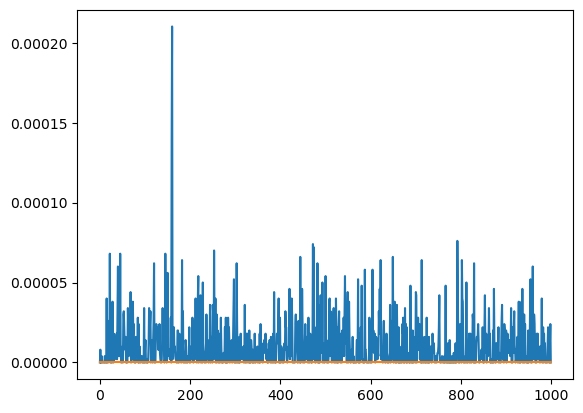

In [ ]:

plt.plot(range(nframe), p1[0])
plt.plot(range(nframe), p2[0])

plt.show()

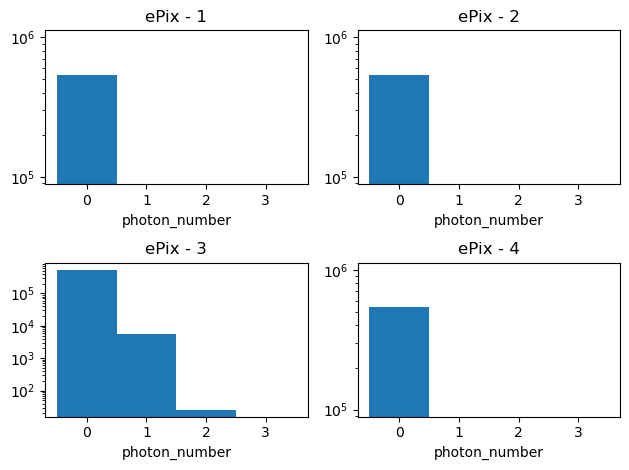

In [ ]:
fig, axs = plt.subplots(2,2,tight_layout=True)
for i, ax in enumerate(np.ravel(axs)):
    ax.hist(imgs_reconstructed[i].flatten(), bins=[-0.5, 0.5, 1.5, 2.5, 3.5])
    ax.set_yscale('log')
    ax.set_xlabel('photon_number')
    ax.set_title(f'ePix - {i+1}')

In [ ]:
beta[1]

IndexError: list index out of range

In [ ]:
plt.plot(range(nframe), beta[1])

IndexError: list index out of range

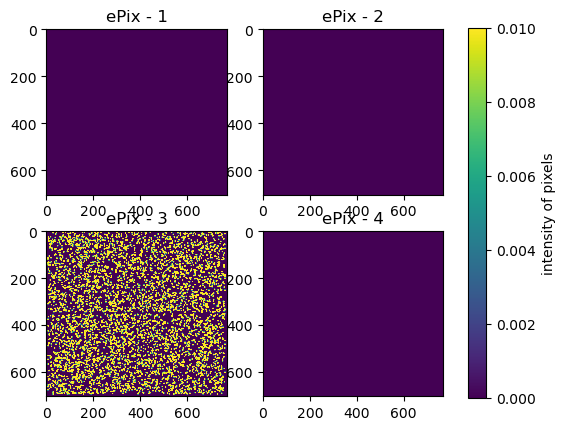

In [ ]:
fig, axs = plt.subplots(2,2)
for i, ax in enumerate(np.ravel(axs)):
    im = ax.imshow(epix_masks[i]*imgs_reconstructed[i], vmax=0.01)
    ax.set_title(f'ePix - {i+1}')
cbar = fig.colorbar(im, ax=axs.ravel().tolist(), label='intensity of pixels')
plt.show()

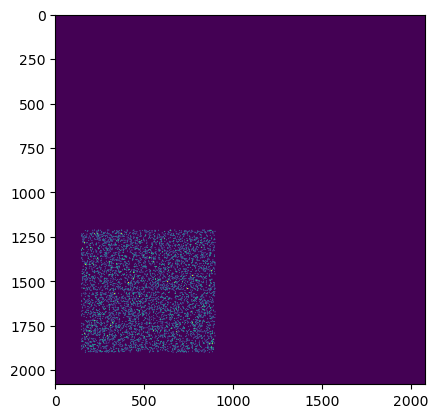

In [ ]:
assembled_img = assemble_image(imgs_reconstructed)
assembled_mask = assemble_image(epix_masks).astype(bool)

plt.imshow(assembled_mask*assembled_img, vmin=0, vmax=0.1)
plt.show()

In [ ]:
epix_poni = str(Path(shared, 'poni', '4epix_Lab6_231103.poni'))
ai = pf.load(epix_poni)
q, Iq = ai.integrate1d(assembled_img,
                      500,
                      mask=(~assembled_mask),
                      unit="q_A^-1",
                      filename=f"epixAll_Iq_run{run}.dat")

(500, 2)


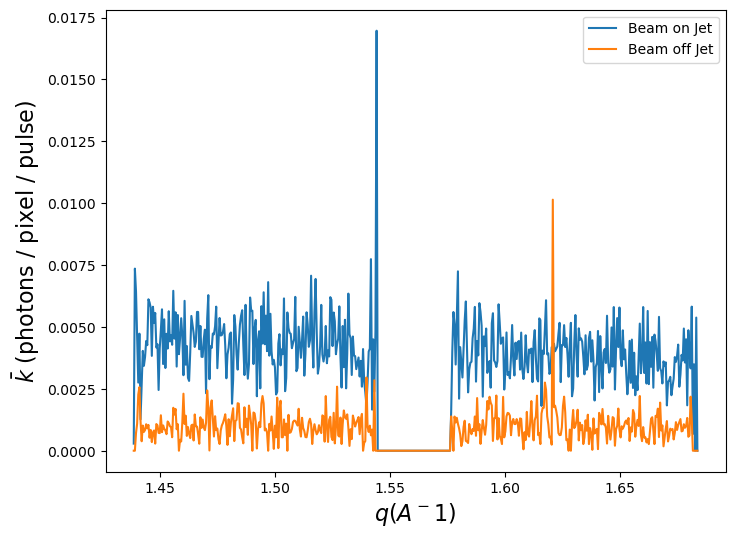

In [ ]:
q0=1.53
q1=1.58
Iq_jetoff = np.loadtxt(str(Path(results, "jason", "epixAll_Iq_run69.dat")))
print(Iq_jetoff.shape)
fig, ax = plt.subplots(figsize=(8,6))
ax.plot(q, Iq, label="Beam on Jet")
ax.plot(q, Iq_jetoff[:,1],label="Beam off Jet")
ax.legend()
ax.set_xlabel('$q (A^-1)$', fontsize=16)
ax.set_ylabel(r'${\bar{k}}$ (photons / pixel / pulse)', fontsize=16)
plt.show()